# Modelling — Early Warning for Long Recorded Activity Spans (Day 30)

**Author:** Ali Čikić · General Assembly – Data Science Bootcamp

This notebook loads the processed data from `01_eda.ipynb`, builds features from the first 30 days of each case,
compares a baseline and the candidate models, explains the final model and its errors, and saves the final model.

## 1. TL;DR

*(Written after running the notebook; every number comes from the outputs below.)*

The final model, **Logistic Regression C**, ranks cases with a long recorded activity span above the others clearly better
than the majority baseline (ROC-AUC 0.710 in cross-validation, 0.708 on the random test and 0.705 on newer cases, versus
0.500 for the baseline). A **tuned Random Forest** scored highest in cross-validation (0.720), but the difference is
smaller than the variation between folds, so the simpler and easier-to-explain Logistic Regression C was selected. The
signal is modest: the model still misses many long cases and is a research result, not a tool ready for real use.

## 2. Recap of the goal

**Research question:** *Can early information from an administrative process help identify cases likely to have a longer
recorded activity span?*

**What we predict.** For each building-permit case, the **recorded activity span** is the number of days between its first
and its last recorded event. A case is **long** if this span is **more than 63 days**. The 63 days are the median of the
956 cases with a recorded end date (see `01_eda.ipynb`): an exploratory threshold, not a legal deadline. The span is what
the event log shows; it is not a verified administrative completion time and not a measure of delay.

**When we predict.** At **day 30** of each case, using only the events recorded in its first 30 days. This makes the task
a **classification**: long or not long, decided early.

**How we measure success.**

- **ROC-AUC** (main measure): how well a model *ranks* long cases above not-long cases, using its predicted probabilities.
  0.5 means no better than chance, 1.0 means perfect. It is **not** the percentage of correct predictions.
- **Precision:** of the cases a model flags as long, the share that really are long (how often a warning is right).
- **Recall:** of the really long cases, the share the model flags (how many long cases it finds).
- **Cases flagged long:** a model that flags almost every case can get high recall without being useful, so the number
  of flagged cases is always shown.

**How we got here.** Earlier stages of the project are summarised in `docs/research_history.md`:

- Regression models predicting the span in days from **whole-case** information (median-baseline MAE 64.42 days, best
  model 51.19 days; a VotingRegressor reached 51.16) — useful practice, but that information only exists after a case ends.
- Features from the **first five events** gave only weak signal (accuracy 0.55 vs 0.51 for the baseline).
- At **day 14**, event counts gave no signal and activity indicators only a little (ROC-AUC 0.53 → 0.59); predicting the
  span in days from day-14 information did not beat a median baseline.
- So the project moved to a later prediction point, **day 30**, which is the subject of this notebook.

## 3. Setup & data loading

**Import the packages.** pandas and matplotlib for tables and charts; scikit-learn for the models, the splits and the
metrics; `hashlib`, `pickle`, `platform` and `tempfile` (part of Python) for small checks and for saving the final model.

In [1]:
import hashlib
import pickle
import platform
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import sklearn
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

**Set the paths from the project folder** (works whether Jupyter starts in the `notebooks` folder or the project folder).
This notebook reads only the processed file made by `01_eda.ipynb`, never the raw XES file.

In [2]:
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
processed_path = project_root / "data" / "processed" / "bpic15_events.csv.gz"
figures_folder = project_root / "docs" / "figures"
results_folder = project_root / "docs" / "results"
models_folder = project_root / "models"
for folder in [figures_folder, results_folder, models_folder]:
    folder.mkdir(parents=True, exist_ok=True)

if not processed_path.exists():
    raise FileNotFoundError("data/processed/bpic15_events.csv.gz is missing. Run notebooks/01_eda.ipynb first.")

**Load the processed event table** with the same loader that was tested in `01_eda.ipynb`: every column is read as text,
only empty cells become missing values (the text `EMPTY` stays a real value), the six date columns become UTC dates and
the fee column becomes a number.

In [3]:
df = pd.read_csv(processed_path, dtype="str", keep_default_na=False, na_values=[""])

date_columns = ["time:timestamp", "case:endDate", "case:startDate", "case:endDatePlanned", "dueDate", "planned"]
for column in date_columns:
    df[column] = pd.to_datetime(df[column], utc=True, format="ISO8601").astype("datetime64[us, UTC]")

df["case:SUMleges"] = df["case:SUMleges"].astype("float64")

**Check that the table is the expected one**: size, number of cases, column types, the columns this notebook needs, and
that the rows are still grouped by case in increasing case order. Each `assert` stops the notebook if the check fails.
Sorted case IDs alone do not prove the exact original row order; that was proven by the exact round-trip check in
section 12 of `01_eda.ipynb`.

In [4]:
print("Rows and columns:", df.shape)
print("Cases:", df["case:concept:name"].nunique())
print("Column types:", df.dtypes.astype(str).value_counts().to_dict())
print("Rows sorted by case ID:", df["case:concept:name"].is_monotonic_increasing)

required_columns = ["case:concept:name", "concept:name", "activityNameEN", "time:timestamp", "org:resource", "case:endDate"]
assert df.shape == (52217, 29), "Unexpected table size: re-run notebooks/01_eda.ipynb"
assert df["case:concept:name"].nunique() == 1199, "Unexpected number of cases"
assert df.dtypes.astype(str).value_counts().to_dict() == {"str": 22, "datetime64[us, UTC]": 6, "float64": 1}, "Unexpected column types"
assert all(column in df.columns for column in required_columns), "A required column is missing"
assert df["case:concept:name"].is_monotonic_increasing, "The rows are no longer in case order"

Rows and columns: (52217, 29)
Cases: 1199
Column types: {'str': 22, 'datetime64[us, UTC]': 6, 'float64': 1}
Rows sorted by case ID: True


The table has the expected 52,217 events, 29 columns and 1,199 cases, with 22 text, 6 date and 1 number columns, still
in case order. All checks passed.

## 4. Feature preparation

### 4.1 Target and day-30 cohort

**Build one row per case** with its first event, last event and recorded end date, calculate the recorded activity span,
and keep the cases with a recorded end date (a recorded end date is not an independently verified completion).
`long_case` is 1 when the span is more than 63 days. Then set each case's **prediction time** to its first event + 30 days
(events recorded **at or before** this time can be used) and keep the cases whose recorded span goes beyond day 30.

In [5]:
case_data = df.groupby("case:concept:name").agg(
    first_event=("time:timestamp", "min"),
    last_event=("time:timestamp", "max"),
    end_date=("case:endDate", "first"),
)
case_data["duration_days"] = (case_data["last_event"] - case_data["first_event"]).dt.total_seconds() / (24 * 60 * 60)
case_data = case_data[case_data["end_date"].notna()]   # cases with a recorded end date only
case_data["long_case"] = (case_data["duration_days"] > 63).astype(int)

case_data["prediction_time"] = case_data["first_event"] + pd.Timedelta(days=30)
active = case_data[case_data["last_event"] > case_data["prediction_time"]]

print("Cases with a recorded end date:", len(case_data))
print("Day-30 eligible cases:", len(active), "| long:", active["long_case"].sum())

Cases with a recorded end date: 956
Day-30 eligible cases: 838 | long: 472


838 cases are eligible at day 30. **Important limitation:** the eligibility rule uses each case's *last* recorded event,
which is only known afterwards. So this is a **retrospective** cohort: in real use, nobody would know at day 30 whether
a case's recorded activity continues. The features below are built correctly from the first 30 days only, but this cohort
rule could not be applied exactly in practice.

### 4.2 Events up to day 30 and the seven count features

**Keep only the events up to each case's day-30 cutoff** and add the activity group of each event (the code prefix, with
the first digit for `01_HOOFD`). These two helpers are copied unchanged from the original research notebooks.

In [6]:
def add_activity_groups(events):
    # the group is the prefix of the activity code, e.g. "02_DRZ" from "02_DRZ_010"
    events = events.copy()
    events["activity_group"] = events["concept:name"].str.extract(r"^(\d{2}_[A-Z0-9]+)_")[0]

    # for the main process 01_HOOFD, add the first digit of the number: "01_HOOFD_065_1" -> "01_HOOFD_0xx"
    is_main = events["activity_group"] == "01_HOOFD"
    first_digit = events.loc[is_main, "concept:name"].str[9]   # "01_HOOFD_" has 9 characters
    events.loc[is_main, "activity_group"] = "01_HOOFD_" + first_digit + "xx"
    return events


grouped_log = add_activity_groups(df)
print("Activity codes:", grouped_log["concept:name"].nunique())
print("Activity groups:", grouped_log["activity_group"].nunique())
print("Events without a group:", grouped_log["activity_group"].isna().sum())

Activity codes: 398
Activity groups: 28
Events without a group: 0


**Keep only the events recorded on or before each case's own day-30 cutoff**, and add `day` (days since the first event).

In [7]:
def events_by_day30(event_table, cases):
    # keep only events of the given cases that happened on or before that case's day-30 cutoff
    events = event_table[event_table["case:concept:name"].isin(cases.index)].copy()
    events["prediction_time"] = events["case:concept:name"].map(cases["prediction_time"])
    events["first_event"] = events["case:concept:name"].map(cases["first_event"])
    first30 = events[events["time:timestamp"] <= events["prediction_time"]].copy()
    first30["day"] = (first30["time:timestamp"] - first30["first_event"]).dt.total_seconds() / (24 * 60 * 60)
    return first30

**The seven count features** (also unchanged). In plain words, for each case:

- `events_first30`: how many events were recorded in the first 30 days;
- `unique_activities_first30`: how many different activity codes;
- `unique_resources_first30`: how many different resources (IDs, not people's names);
- `repeated_activities_first30`: events minus different activities (how much was repeated);
- `events_first15` and `events_days16_30`: events in the first and the second half of the 30 days;
- `days_since_last_event`: how many days had passed since the last recorded event at day 30.

Two of them are exact combinations of others (repeated = events − different activities; days 16–30 = all − first 15).
They are kept so the results match the original research, and their coefficients are not interpreted one by one.

In [8]:
count_columns = [
    "events_first30",
    "unique_activities_first30",
    "unique_resources_first30",
    "repeated_activities_first30",
    "events_first15",
    "events_days16_30",
    "days_since_last_event",
]


def count_features(first30, cases):
    first30 = first30.copy()
    first30["in_first15"] = first30["day"] <= 15
    features = first30.groupby("case:concept:name").agg(
        events_first30=("concept:name", "size"),
        unique_activities_first30=("concept:name", "nunique"),
        unique_resources_first30=("org:resource", "nunique"),
        events_first15=("in_first15", "sum"),
        last_event_by_day30=("time:timestamp", "max"),
    )
    features["repeated_activities_first30"] = features["events_first30"] - features["unique_activities_first30"]
    features["events_days16_30"] = features["events_first30"] - features["events_first15"]
    features["days_since_last_event"] = (
        cases.loc[features.index, "prediction_time"] - features["last_event_by_day30"]
    ).dt.total_seconds() / (24 * 60 * 60)
    return features[count_columns]

**Calculate the count features for all 838 eligible cases** and check that no event after day 30 was used.

In [9]:
first30 = add_activity_groups(events_by_day30(df, active))
counts = count_features(first30, active)
y = active.loc[counts.index, "long_case"]

print("Events recorded by day 30:", len(first30))
print("Latest event used, in days after the case start:", first30["day"].max())
print("Every event used is on or before its case's cutoff:", (first30["time:timestamp"] <= first30["prediction_time"]).all())
counts.head()

Events recorded by day 30: 14551
Latest event used, in days after the case start: 30.0
Every event used is on or before its case's cutoff: True


,events_first30,unique_activities_first30,unique_resources_first30,repeated_activities_first30,events_first15,events_days16_30,days_since_last_event
case:concept:name,,,,,,,
10009138,13,13,1,0,13,0,26.599109
10051383,13,13,1,0,13,0,29.390127
10053042,13,13,1,0,13,0,26.375428
10093171,12,12,1,0,12,0,22.472326
10186644,14,14,1,0,14,0,15.523646


Each row is one case and each value is calculated from that case's first 30 days only. These counts need no training:
they are the same whatever cases are used for training.

### 4.3 Features learned from training cases

Some features depend on **which cases are used for training**: which activity codes to use, which activity groups, the
PCA components and the TF-IDF words. They are therefore always chosen on the **training cases only** (and again inside
every cross-validation fold) and then simply applied to the validation or test cases. The helpers below are copied
unchanged from the original notebooks 14, 15 and 16.

**Activity indicators:** the 15 activity codes recorded in 10–90% of the training cases (most frequent first, ties by
code); 1 if the code was recorded by day 30, otherwise 0.

In [10]:
def select_activities(first30, case_ids):
    # activity codes recorded in 10-90% of the given cases, at most 15, most frequent first (ties by code)
    events = first30[first30["case:concept:name"].isin(case_ids)]
    share = events.groupby("concept:name")["case:concept:name"].nunique() / len(case_ids) * 100
    share = share.rename("train_cases_pct").reset_index()
    share = share[(share["train_cases_pct"] >= 10) & (share["train_cases_pct"] <= 90)]
    share = share.sort_values(["train_cases_pct", "concept:name"], ascending=[False, True])
    return share.head(15)["concept:name"].tolist()


def activity_flags(first30, activities, case_ids):
    # 1 if the activity was recorded by day 30 in that case, otherwise 0
    flags = pd.DataFrame(index=case_ids)
    for activity in activities:
        cases_with_activity = first30.loc[first30["concept:name"] == activity, "case:concept:name"].unique()
        flags["act_" + activity] = flags.index.isin(cases_with_activity).astype(int)
    return flags

**Activity groups:** groups recorded in at least 5% of the training cases (except the near-universal `01_HOOFD_0xx`), one
0/1 column each, plus `grp_other_group` for the rare ones; and `highest_main_stage`, the highest `01_HOOFD` digit reached
by day 30, an exploratory stand-in for how far the main process had progressed (the source-system meaning of the code
prefixes is not fully documented).

In [11]:
def select_groups(first30, case_ids):
    # activity groups recorded by day 30 in at least 5% of the given cases, except 01_HOOFD_0xx
    events = first30[first30["case:concept:name"].isin(case_ids)]
    share = events.groupby("activity_group")["case:concept:name"].nunique() / len(case_ids) * 100
    groups = share[share >= 5].index.tolist()
    groups.remove("01_HOOFD_0xx")
    return sorted(groups)

**Turn the chosen groups into 0/1 columns**, with one extra column for all rare groups.

In [12]:
def group_flags(first30, groups, case_ids):
    # 1 if the group was recorded by day 30 in that case, otherwise 0
    flags = pd.DataFrame(index=case_ids)
    for group in groups:
        cases_with_group = first30.loc[first30["activity_group"] == group, "case:concept:name"].unique()
        flags["grp_" + group] = flags.index.isin(cases_with_group).astype(int)

    # every rare group (not selected and not 01_HOOFD_0xx) goes into one column
    rare_events = first30[~first30["activity_group"].isin(groups + ["01_HOOFD_0xx"])]
    flags["grp_other_group"] = flags.index.isin(rare_events["case:concept:name"].unique()).astype(int)
    return flags

**The progress stand-in:** the highest `01_HOOFD` digit recorded by day 30 (0 if none).

In [13]:
def highest_main_stage(first30, case_ids):
    # highest first digit of a 01_HOOFD code recorded by day 30, e.g. 4 for "01_HOOFD_4xx"
    main_events = first30[first30["activity_group"].str.startswith("01_HOOFD_")]
    stages = main_events["activity_group"].str[9].astype(int)
    highest = stages.groupby(main_events["case:concept:name"]).max()
    return highest.reindex(case_ids).fillna(0).astype(int).rename("highest_main_stage")

**PCA inputs:** every activity code seen in the training cases becomes a 0/1 column (one-hot encoding per event, then
"recorded at least once" per case); PCA then compresses these columns into a few components, fitted on the training
cases only.

In [14]:
def select_vocabulary(first30, case_ids):
    # every activity code recorded by day 30 in at least one of the given (training) cases
    events = first30[first30["case:concept:name"].isin(case_ids)]
    return sorted(events["concept:name"].unique())

**One 0/1 column per activity code of the training vocabulary** (codes never seen in training are ignored).

In [15]:
def activity_indicators(first30, vocabulary, case_ids):
    events = first30[first30["case:concept:name"].isin(case_ids)]
    one_hot = pd.get_dummies(events["concept:name"], dtype=int)    # one row per event, one column per code
    one_hot["case"] = events["case:concept:name"].values
    per_case = one_hot.groupby("case").max()                        # 1 if the code was recorded by day 30
    return per_case.reindex(index=case_ids, columns=vocabulary, fill_value=0)

**Fit PCA on the training indicators only**, transform both groups and put the 7 counts next to the components.

In [16]:
def pca_features(train_ids, other_ids, n_components):
    vocabulary = select_vocabulary(first30, train_ids)
    train_indicators = activity_indicators(first30, vocabulary, train_ids)
    other_indicators = activity_indicators(first30, vocabulary, other_ids)

    pca = PCA(n_components=n_components, svd_solver="full").fit(train_indicators)   # training cases only

    component_names = ["pc_" + str(number) for number in range(1, n_components + 1)]
    train_components = pd.DataFrame(pca.transform(train_indicators), index=train_ids, columns=component_names)
    other_components = pd.DataFrame(pca.transform(other_indicators), index=other_ids, columns=component_names)

    X_train = counts.loc[train_ids].join(train_components)
    X_other = counts.loc[other_ids].join(other_components)
    return X_train, X_other, pca

**TF-IDF text features:** for each case, the distinct English activity descriptions recorded by day 30 joined into one
text; TF-IDF turns the text into 30 word columns (common words get lower weights), fitted on training cases only.

In [17]:
def case_documents(first30, case_ids):
    # one text per case: every distinct English description recorded by day 30, joined with spaces
    events = first30[first30["case:concept:name"].isin(case_ids)]
    unique_descriptions = events[["case:concept:name", "activityNameEN"]].drop_duplicates()
    documents = unique_descriptions.groupby("case:concept:name")["activityNameEN"].agg(" ".join)
    return documents.reindex(case_ids, fill_value="")

**Fit TF-IDF on the training texts only** (30 words, a word must appear in at least 3 cases, common English words left out).

In [18]:
def text_features(train_ids, other_ids):
    vectorizer = TfidfVectorizer(max_features=30, min_df=3, stop_words="english")
    train_matrix = vectorizer.fit_transform(case_documents(first30, train_ids))   # training cases only
    other_matrix = vectorizer.transform(case_documents(first30, other_ids))

    column_names = ["txt_" + word for word in vectorizer.get_feature_names_out()]
    train_text = pd.DataFrame(train_matrix.toarray(), index=train_ids, columns=column_names)
    other_text = pd.DataFrame(other_matrix.toarray(), index=other_ids, columns=column_names)
    return train_text, other_text

### 4.4 The feature sets

**One small function per feature set.** Each receives the training cases and the cases to predict, learns its choices on
the training cases only, and returns the two feature tables. The column order is the same as in the original research.

- **Baseline:** the counts (the baseline ignores them).
- **A. Original:** 7 counts + 15 activity indicators.
- **B. Grouped:** 7 counts + group indicators + `highest_main_stage`.
- **C. Combined:** A + group indicators + `highest_main_stage` (**the final model's features**).

In [19]:
def features_counts(train_ids, other_ids):
    return counts.loc[train_ids], counts.loc[other_ids]


def features_A(train_ids, other_ids):
    activities = select_activities(first30, train_ids)
    X_train = counts.loc[train_ids].join(activity_flags(first30, activities, train_ids))
    X_other = counts.loc[other_ids].join(activity_flags(first30, activities, other_ids))
    return X_train, X_other


def features_B(train_ids, other_ids):
    groups = select_groups(first30, train_ids)
    X_train = counts.loc[train_ids].join(group_flags(first30, groups, train_ids)).join(highest_main_stage(first30, train_ids))
    X_other = counts.loc[other_ids].join(group_flags(first30, groups, other_ids)).join(highest_main_stage(first30, other_ids))
    return X_train, X_other


def features_C(train_ids, other_ids):
    groups = select_groups(first30, train_ids)
    X_train, X_other = features_A(train_ids, other_ids)
    X_train = X_train.join(group_flags(first30, groups, train_ids)).join(highest_main_stage(first30, train_ids))
    X_other = X_other.join(group_flags(first30, groups, other_ids)).join(highest_main_stage(first30, other_ids))
    return X_train, X_other

- **D. PCA:** 7 counts + PCA components of all activity indicators, with **5, 10 or 20** components (fixed in advance;
  the number is chosen by cross-validation in section 7).
- **E. TF-IDF:** C + 30 TF-IDF word columns.

In [20]:
def features_D5(train_ids, other_ids):
    X_train, X_other, pca = pca_features(train_ids, other_ids, 5)
    return X_train, X_other


def features_D10(train_ids, other_ids):
    X_train, X_other, pca = pca_features(train_ids, other_ids, 10)
    return X_train, X_other


def features_D20(train_ids, other_ids):
    X_train, X_other, pca = pca_features(train_ids, other_ids, 20)
    return X_train, X_other


def features_E(train_ids, other_ids):
    X_train, X_other = features_C(train_ids, other_ids)
    train_text, other_text = text_features(train_ids, other_ids)
    return X_train.join(train_text), X_other.join(other_text)

## 5. Train/test split

Two ways of keeping test cases apart, both exactly as in the original research.

### 5.1 Random split

The random split was first made at day 14 (733 training / 184 test cases, stratified by `long_case`, `random_state=42`).
**Rebuild it with the same code and then keep its day-30 cases**, so training cases stay in training and test cases in
test; nothing is redrawn.

In [21]:
day14_cases = case_data[case_data["last_event"] > case_data["first_event"] + pd.Timedelta(days=14)]
original_train_ids, original_test_ids = train_test_split(
    day14_cases.index, test_size=0.20, random_state=42, stratify=day14_cases["long_case"]
)

random_train_ids = [case for case in original_train_ids if case in active.index]
random_test_ids = [case for case in original_test_ids if case in active.index]

print("Random training cases:", len(random_train_ids), "| long:", y.loc[random_train_ids].sum())
print("Random test cases:", len(random_test_ids), "| long:", y.loc[random_test_ids].sum())
print("Overlap:", len(set(random_train_ids) & set(random_test_ids)))

Random training cases: 677 | long: 377
Random test cases: 161 | long: 95
Overlap: 0


### 5.2 Temporal split

**Train on older cases and test on the newest 20%.** The cases are sorted by their day-30 prediction time; the boundary
is the prediction time at the start of the newest 20%. Older cases are used for training only if both their last event
and their recorded end date are before the boundary, because otherwise their outcome would not yet have been known.

In [22]:
sorted_cases = active.sort_values("prediction_time", kind="stable")
boundary = sorted_cases["prediction_time"].iloc[int(len(sorted_cases) * 0.8)]

temporal_test = sorted_cases[sorted_cases["prediction_time"] >= boundary]
candidates = sorted_cases[sorted_cases["prediction_time"] < boundary]
temporal_train = candidates[(candidates["last_event"] < boundary) & (candidates["end_date"] < boundary)]
temporal_train_ids, temporal_test_ids = temporal_train.index, temporal_test.index

print("Boundary:", boundary)
print("Temporal training cases:", len(temporal_train_ids), "| long:", y.loc[temporal_train_ids].sum())
print("Temporal test cases:", len(temporal_test_ids), "| long:", y.loc[temporal_test_ids].sum())
print("Overlap:", len(set(temporal_train_ids) & set(temporal_test_ids)))
print("Temporal test cases that were random-split TRAINING cases:", len(set(temporal_test_ids) & set(random_train_ids)))

Boundary: 2013-10-25 22:00:00+00:00
Temporal training cases: 617 | long: 328
Temporal test cases: 168 | long: 100
Overlap: 0
Temporal test cases that were random-split TRAINING cases: 138


Both splits keep training and test cases apart. But 138 of the 168 temporal test cases were **training** cases in the
random split, and the models were designed while looking at the random-split results. The temporal test is therefore a
**chronological robustness check**, not an untouched independent final test.

### 5.3 Cross-validation folds

**Make the five folds** of the random training cases (`StratifiedKFold`, `shuffle=True`, `random_state=42`). In every
fold, four parts train the model and the fifth part checks it. Every candidate uses exactly the same folds.

In [23]:
fold_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_index = pd.Index(random_train_ids)

folds = []
for fit_positions, val_positions in fold_splitter.split(train_index, y.loc[train_index]):
    folds.append((train_index[fit_positions], train_index[val_positions]))

print("Fold sizes (training part / validation part):", [(len(fit), len(val)) for fit, val in folds])

Fold sizes (training part / validation part): [(541, 136), (541, 136), (542, 135), (542, 135), (542, 135)]


**Fingerprints of the case lists.** A fingerprint is a short code calculated from the case IDs in their order; it changes
if any case or the order changes. These codes let anyone check that the cohort, the splits and the folds are exactly the
ones used in the original research.

In [24]:
def fingerprint(case_ids):
    text = ",".join(case_ids)
    return hashlib.sha256(text.encode("utf-8")).hexdigest()[:12]


fingerprints = {
    "Day-30 cohort": fingerprint(active.index),
    "Random training": fingerprint(random_train_ids),
    "Random test": fingerprint(random_test_ids),
    "Temporal training": fingerprint(temporal_train_ids),
    "Temporal test": fingerprint(temporal_test_ids),
}
for number, (fit_ids, val_ids) in enumerate(folds, start=1):
    fingerprints[f"Fold {number} validation"] = fingerprint(val_ids)

for name, value in fingerprints.items():
    print(f"{name:<20} {value}")


Day-30 cohort        61bd3223a61a
Random training      8bbf28b872ef
Random test          b61f90db951c
Temporal training    b64b3f84df61
Temporal test        539991dace08
Fold 1 validation    5725935e75ee
Fold 2 validation    d82260a7d7ef
Fold 3 validation    4f123aef50fb
Fold 4 validation    a87091153df7
Fold 5 validation    ba7501a13748


**Compare with the reference fingerprints and check that no case is in both parts.** The reference codes below were
calculated from the raw XES file with the original research code, independently of this notebook. If the cohort, a
split, a fold or the case order changed, the first `assert` stops the notebook. The other checks confirm that training
and test cases never overlap within one evaluation. (The 138 temporal test cases that were random-split training cases,
shown in section 5.2, are a different matter: they connect two separate evaluations, a known limitation, not an overlap
inside one.)

In [25]:
reference_fingerprints = {
    "Day-30 cohort": "61bd3223a61a",
    "Random training": "8bbf28b872ef",
    "Random test": "b61f90db951c",
    "Temporal training": "b64b3f84df61",
    "Temporal test": "539991dace08",
    "Fold 1 validation": "5725935e75ee",
    "Fold 2 validation": "d82260a7d7ef",
    "Fold 3 validation": "4f123aef50fb",
    "Fold 4 validation": "a87091153df7",
    "Fold 5 validation": "ba7501a13748",
}
assert fingerprints == reference_fingerprints, "The cohort, a split or a fold differs from the original research"

assert not set(random_train_ids) & set(random_test_ids), "Random split: a case is in training and test"
assert not set(temporal_train_ids) & set(temporal_test_ids), "Temporal split: a case is in training and test"
for fit_ids, val_ids in folds:
    assert not set(fit_ids) & set(val_ids), "A fold has a case in both parts"
print("All 10 fingerprints match the original research, and no evaluation has a case in both training and test.")


All 10 fingerprints match the original research, and no evaluation has a case in both training and test.


### 5.4 Check: no future information in the features

**Change every event after each case's day-30 cutoff** to fake values (activity, resource and English description) and
rebuild every kind of feature with the same helpers. If the features only use events up to day 30, nothing may change.

In [26]:
changed = df.copy()
after_day30 = changed["time:timestamp"] > changed["case:concept:name"].map(active["prediction_time"])
changed.loc[after_day30, "concept:name"] = "FAKE_ACTIVITY"
changed.loc[after_day30, "org:resource"] = "FAKE_RESOURCE"
changed.loc[after_day30, "activityNameEN"] = "fake future description"
changed_first30 = add_activity_groups(events_by_day30(changed, active))

all_ids = list(counts.index)
check_activities = select_activities(first30, random_train_ids)
check_groups = select_groups(first30, random_train_ids)
check_vocabulary = select_vocabulary(first30, random_train_ids)

**Rebuild every kind of feature from the changed events and compare it with the original features.**

In [27]:
checks = {
    "count features": count_features(changed_first30, active).loc[all_ids].equals(counts.loc[all_ids]),
    "activity indicators": activity_flags(changed_first30, check_activities, all_ids).equals(activity_flags(first30, check_activities, all_ids)),
    "group indicators": group_flags(changed_first30, check_groups, all_ids).equals(group_flags(first30, check_groups, all_ids)),
    "highest main stage": highest_main_stage(changed_first30, all_ids).equals(highest_main_stage(first30, all_ids)),
    "PCA inputs": activity_indicators(changed_first30, check_vocabulary, all_ids).equals(activity_indicators(first30, check_vocabulary, all_ids)),
    "TF-IDF texts": case_documents(changed_first30, all_ids).equals(case_documents(first30, all_ids)),
}
print("Events changed:", after_day30.sum())
for name, unchanged in checks.items():
    print(f"{name:<20} unchanged: {unchanged}")

assert all(checks.values()), "Future information changed the Day-30 features."

Events changed: 26120
count features       unchanged: True
activity indicators  unchanged: True
group indicators     unchanged: True
highest main stage   unchanged: True
PCA inputs           unchanged: True
TF-IDF texts         unchanged: True


All feature inputs stay identical (the `assert` would stop the notebook otherwise), so no information from after day
30 enters the features. This checks **feature
timing** only. It does not remove the retrospective cohort rule (section 4.1), and it cannot show whether a real system
would know which cases are still open at day 30.

## 6. Baseline model

**One function for all metrics**, so every model is scored the same way. ROC-AUC uses the predicted probabilities; the
other metrics use the 0/1 predictions at the default threshold of 0.5 (the threshold is never tuned).

In [28]:
def classification_metrics(model, X, y_true):
    predictions = model.predict(X)
    return {
        "ROC-AUC": roc_auc_score(y_true, model.predict_proba(X)[:, 1]),
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions),
        "F1": f1_score(y_true, predictions),
        "Cases flagged long": int(predictions.sum()),
    }

**Train on some cases and score on others** (`fit_and_score`), and **repeat that over the five folds**
(`cross_validate`). `clone` makes a fresh, untrained copy of the model with the same settings every time.

In [29]:
def fit_and_score(feature_function, model, train_ids, test_ids):
    X_train, X_test = feature_function(train_ids, test_ids)
    fitted_model = clone(model).fit(X_train, y.loc[train_ids])
    return classification_metrics(fitted_model, X_test, y.loc[test_ids])


def cross_validate(name, feature_function, model):
    rows = []
    for number, (fit_ids, val_ids) in enumerate(folds, start=1):
        row = fit_and_score(feature_function, model, fit_ids, val_ids)
        row["Model"] = name
        row["Fold"] = number
        rows.append(row)
    return rows

**The majority baseline** always predicts the most common class of its training cases ("long") and gives every case the
same probability. Any useful model has to beat it.

In [30]:
baseline = DummyClassifier(strategy="most_frequent")
cv_rows = cross_validate("Majority baseline", features_counts, baseline)

baseline_random = fit_and_score(features_counts, baseline, random_train_ids, random_test_ids)
baseline_temporal = fit_and_score(features_counts, baseline, temporal_train_ids, temporal_test_ids)
pd.DataFrame({"Random test": baseline_random, "Temporal test": baseline_temporal}).round(3)

,Random test,Temporal test
ROC-AUC,0.500,0.500
Accuracy,0.590,0.595
Precision,0.590,0.595
Recall,1.000,1.000
F1,0.742,0.746
Cases flagged long,161.000,168.000


The baseline flags **every** case as long, so its recall is 1.00 and its precision equals the share of long cases (59.0%
and 59.5%). Its ROC-AUC is **0.500**: it cannot tell any two cases apart. This is why high recall alone means nothing
and ROC-AUC is the main measure.

## 7. Candidate models

All candidates use the same folds and the same tests, and every learned choice is made on training data only. No setting
is tuned on the test cases.

### 7.1 Logistic Regression with different feature sets

**Logistic Regression** (`StandardScaler` + `LogisticRegression(max_iter=1000)`) is the main simple model: it is fast,
and its coefficients can be explained. The scaler is part of the pipeline, so it is fitted on the training cases only.
The feature sets test the reviewer's recommendations: activity groups (B, C), one-hot encoding + PCA (D) and text
features (E).

In [31]:
logistic_regression = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

logistic_candidates = [
    ("Logistic Regression A", features_A),
    ("Logistic Regression B", features_B),
    ("Logistic Regression C", features_C),
    ("Logistic Regression D (PCA, 5 components)", features_D5),
    ("Logistic Regression D (PCA, 10 components)", features_D10),
    ("Logistic Regression D (PCA, 20 components)", features_D20),
    ("Logistic Regression E (TF-IDF)", features_E),
]
for name, feature_function in logistic_candidates:
    cv_rows += cross_validate(name, feature_function, logistic_regression)

### 7.2 Random Forest and Gradient Boosting: original settings and tuning

**Ensembles** combine many decision trees and can capture non-linear patterns. Both use features A (7 counts + 15
activity indicators). The **original** settings come from the first comparison; then a **small grid fixed in advance**
is tested, as recommended by the reviewer:

- Random Forest: `n_estimators` 100 or 200 (number of trees), `max_depth` 3, 5 or None (how deep each tree may grow),
  `min_samples_leaf` 1 or 3 (smallest group of cases at the end of a branch) — 12 combinations.
- Gradient Boosting: `n_estimators` 50 or 100, `learning_rate` 0.05 or 0.1 (size of each correction), `max_depth` 2 or 3
  — 8 combinations. Settings not in the grid keep scikit-learn's defaults.

In [32]:
ensemble_settings = [("Random Forest (original)", RandomForestClassifier(n_estimators=100, max_depth=4, min_samples_leaf=10, random_state=42)),
                     ("Gradient Boosting (original)", GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=2,
                                                                                 min_samples_leaf=10, random_state=42))]

grid_number = 0
for n_estimators in [100, 200]:
    for max_depth in [3, 5, None]:
        for min_samples_leaf in [1, 3]:
            grid_number += 1
            model = RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth,
                                           min_samples_leaf=min_samples_leaf, random_state=42)
            ensemble_settings.append((f"Random Forest grid {grid_number}", model))

grid_number = 0
for n_estimators in [50, 100]:
    for learning_rate in [0.05, 0.1]:
        for max_depth in [2, 3]:
            grid_number += 1
            model = GradientBoostingClassifier(n_estimators=n_estimators, learning_rate=learning_rate,
                                               max_depth=max_depth, random_state=42)
            ensemble_settings.append((f"Gradient Boosting grid {grid_number}", model))

print("Ensemble settings to cross-validate:", len(ensemble_settings))

Ensemble settings to cross-validate: 22


**Cross-validate every ensemble setting** with features A (this takes about half a minute).

In [33]:
for name, model in ensemble_settings:
    cv_rows += cross_validate(name, features_A, model)

cv_results = pd.DataFrame(cv_rows)
cv_summary = cv_results.groupby("Model", sort=False)["ROC-AUC"].agg(["mean", "std"])
print("Models cross-validated:", len(cv_summary), "| fold results:", len(cv_results))

Models cross-validated: 30 | fold results: 150


### 7.3 Choices made with cross-validation only

**Pick the number of PCA components and the tuned ensemble settings** with the highest mean cross-validation ROC-AUC
(ties go to the first in the list). The test cases play no part in these choices.

In [34]:
pca_options = {5: features_D5, 10: features_D10, 20: features_D20}
pca_scores = {}
for n in pca_options:
    pca_scores[n] = round(float(cv_summary.loc[f"Logistic Regression D (PCA, {n} components)", "mean"]), 3)
best_components = max(pca_scores, key=pca_scores.get)

random_forest_grid = cv_summary.loc[[name for name, model in ensemble_settings if name.startswith("Random Forest grid")], "mean"]
boosting_grid = cv_summary.loc[[name for name, model in ensemble_settings if name.startswith("Gradient Boosting grid")], "mean"]
models_by_name = dict(ensemble_settings)
tuned_random_forest = models_by_name[random_forest_grid.idxmax()]
tuned_boosting = models_by_name[boosting_grid.idxmax()]

print("PCA components (mean CV ROC-AUC):", pca_scores, "-> chosen:", best_components)
print("Tuned Random Forest:", random_forest_grid.idxmax(), tuned_random_forest.get_params()["n_estimators"],
      "trees, max_depth", tuned_random_forest.get_params()["max_depth"], ", min_samples_leaf", tuned_random_forest.get_params()["min_samples_leaf"])
print("Tuned Gradient Boosting:", boosting_grid.idxmax(), tuned_boosting.get_params()["n_estimators"],
      "trees, learning_rate", tuned_boosting.get_params()["learning_rate"], ", max_depth", tuned_boosting.get_params()["max_depth"])

PCA components (mean CV ROC-AUC): {5: 0.675, 10: 0.709, 20: 0.697} -> chosen: 10
Tuned Random Forest: Random Forest grid 9 200 trees, max_depth 5 , min_samples_leaf 1
Tuned Gradient Boosting: Gradient Boosting grid 2 50 trees, learning_rate 0.05 , max_depth 3


Ten PCA components and the settings above were chosen by cross-validation. **All 20 tested grid settings** with their
scores are saved to `docs/results/day30_tuning_results.csv`, including the ones that did worse.

In [35]:
tuning_rows = []
for name, model in ensemble_settings:
    settings = model.get_params()
    tuning_rows.append({
        "Setting": name,
        "n_estimators": settings["n_estimators"],
        "max_depth": str(settings["max_depth"]),
        "min_samples_leaf": settings["min_samples_leaf"],
        "learning_rate": settings.get("learning_rate", ""),
        "CV ROC-AUC mean": cv_summary.loc[name, "mean"],
        "CV ROC-AUC std": cv_summary.loc[name, "std"],
    })
tuning_table = pd.DataFrame(tuning_rows)
tuning_table.to_csv(results_folder / "day30_tuning_results.csv", index=False)
tuning_table.round(3)

,Setting,n_estimators,max_depth,min_samples_leaf,learning_rate,CV ROC-AUC mean,CV ROC-AUC std
0,Random Forest (original),100,4,10,,0.701,0.042
1,Gradient Boosting (original),100,2,10,0.05,0.684,0.044
2,Random Forest grid 1,100,3,1,,0.704,0.042
3,Random Forest grid 2,100,3,3,,0.704,0.042
4,Random Forest grid 3,100,5,1,,0.719,0.031
5,Random Forest grid 4,100,5,3,,0.717,0.029
6,Random Forest grid 5,100,None,1,,0.672,0.019
7,Random Forest grid 6,100,None,3,,0.714,0.022
8,Random Forest grid 7,200,3,1,,0.700,0.038
9,Random Forest grid 8,200,3,3,,0.701,0.037


For Random Forest, trees of depth 5 did best, and unlimited trees with 1-case leaves did clearly worse (they fit the
training cases too closely). For Gradient Boosting all settings were close together.

### 7.4 The final candidates on the test cases

**Score each final candidate once on the random test and once on the temporal test.** Every model is trained again on the
training cases of that split, with its choices learned on those training cases only.

In [36]:
final_candidates = [
    ("Majority baseline", features_counts, baseline),
    ("Logistic Regression A", features_A, logistic_regression),
    ("Logistic Regression B", features_B, logistic_regression),
    ("Logistic Regression C", features_C, logistic_regression),
    (f"Logistic Regression D (PCA, {best_components} components)", pca_options[best_components], logistic_regression),
    ("Logistic Regression E (TF-IDF)", features_E, logistic_regression),
    ("Random Forest (original)", features_A, models_by_name["Random Forest (original)"]),
    ("Gradient Boosting (original)", features_A, models_by_name["Gradient Boosting (original)"]),
    ("Random Forest (tuned)", features_A, tuned_random_forest),
    ("Gradient Boosting (tuned)", features_A, tuned_boosting),
]

test_rows = []
for name, feature_function, model in final_candidates:
    for split_name, train_ids, test_ids in [("Random test", random_train_ids, random_test_ids),
                                            ("Temporal test", temporal_train_ids, temporal_test_ids)]:
        row = fit_and_score(feature_function, model, train_ids, test_ids)
        row["Model"] = name
        row["Test"] = split_name
        test_rows.append(row)
test_results = pd.DataFrame(test_rows)
print("Test evaluations:", len(test_results))

Test evaluations: 20


## 8. Evaluation & comparison

### 8.1 Results table

**Put the cross-validation and test results of all final candidates into one table.** The CV names of the tuned models
are mapped to "(tuned)".

In [37]:
cv_name = {name: name for name, feature_function, model in final_candidates}
cv_name["Random Forest (tuned)"] = random_forest_grid.idxmax()
cv_name["Gradient Boosting (tuned)"] = boosting_grid.idxmax()

comparison_rows = []
for name, feature_function, model in final_candidates:
    random_row = test_results[(test_results["Model"] == name) & (test_results["Test"] == "Random test")].iloc[0]
    temporal_row = test_results[(test_results["Model"] == name) & (test_results["Test"] == "Temporal test")].iloc[0]
    comparison_rows.append({
        "Model": name,
        "CV ROC-AUC": cv_summary.loc[cv_name[name], "mean"],
        "CV std": cv_summary.loc[cv_name[name], "std"],
        "Random ROC-AUC": random_row["ROC-AUC"],
        "Random precision": random_row["Precision"],
        "Random recall": random_row["Recall"],
        "Random flagged (of 161)": random_row["Cases flagged long"],
        "Temporal ROC-AUC": temporal_row["ROC-AUC"],
        "Temporal precision": temporal_row["Precision"],
        "Temporal recall": temporal_row["Recall"],
        "Temporal flagged (of 168)": temporal_row["Cases flagged long"],
    })
comparison = pd.DataFrame(comparison_rows).set_index("Model")
comparison.to_csv(results_folder / "day30_model_comparison.csv")
comparison.round(3)

,CV ROC-AUC,CV std,Random ROC-AUC,Random precision,Random recall,Random flagged (of 161),Temporal ROC-AUC,Temporal precision,Temporal recall,Temporal flagged (of 168)
Model,,,,,,,,,,
Majority baseline,0.500,0.000,0.500,0.590,1.000,161,0.500,0.595,1.00,168
Logistic Regression A,0.702,0.033,0.659,0.694,0.716,98,0.678,0.775,0.55,71
Logistic Regression B,0.694,0.034,0.680,0.674,0.653,92,0.709,0.644,0.85,132
Logistic Regression C,0.710,0.017,0.708,0.730,0.768,100,0.705,0.847,0.50,59
"Logistic Regression D (PCA, 10 components)",0.709,0.036,0.721,0.716,0.768,102,0.729,0.828,0.53,64
Logistic Regression E (TF-IDF),0.702,0.033,0.725,0.732,0.747,97,0.657,0.830,0.44,53
Random Forest (original),0.701,0.042,0.745,0.695,0.863,118,0.674,0.843,0.43,51
Gradient Boosting (original),0.684,0.044,0.723,0.697,0.800,109,0.624,0.875,0.35,40
Random Forest (tuned),0.720,0.035,0.752,0.708,0.842,113,0.709,0.894,0.42,47


**Check against the original research.** The values below were copied from the outputs of the original notebooks 12 and
14–17. They are used **only** to check that this notebook reproduces those results; every number in the table above was
calculated by running the models.

In [38]:
reference = {   # same column order as the table: CV ROC-AUC, CV std, random ROC-AUC, random precision, random recall,
                # random flagged, temporal ROC-AUC, temporal precision, temporal recall, temporal flagged
    "Majority baseline": (0.500, 0.000, 0.500, 0.590, 1.000, 161, 0.500, 0.595, 1.000, 168),
    "Logistic Regression A": (0.702, 0.033, 0.659, 0.694, 0.716, 98, 0.678, 0.775, 0.550, 71),
    "Logistic Regression B": (0.694, 0.034, 0.680, 0.674, 0.653, 92, 0.709, 0.644, 0.850, 132),
    "Logistic Regression C": (0.710, 0.017, 0.708, 0.730, 0.768, 100, 0.705, 0.847, 0.500, 59),
    "Logistic Regression D (PCA, 10 components)": (0.709, 0.036, 0.721, 0.716, 0.768, 102, 0.729, 0.828, 0.530, 64),
    "Logistic Regression E (TF-IDF)": (0.702, 0.033, 0.725, 0.732, 0.747, 97, 0.657, 0.830, 0.440, 53),
    "Random Forest (original)": (0.701, 0.042, 0.745, 0.695, 0.863, 118, 0.674, 0.843, 0.430, 51),
    "Gradient Boosting (original)": (0.684, 0.044, 0.723, 0.697, 0.800, 109, 0.624, 0.875, 0.350, 40),
    "Random Forest (tuned)": (0.720, 0.035, 0.752, 0.708, 0.842, 113, 0.709, 0.894, 0.420, 47),
    "Gradient Boosting (tuned)": (0.710, 0.029, 0.726, 0.681, 0.853, 119, 0.636, 0.872, 0.340, 39),
}
assert list(comparison.columns) == ["CV ROC-AUC", "CV std", "Random ROC-AUC", "Random precision", "Random recall",
                                    "Random flagged (of 161)", "Temporal ROC-AUC", "Temporal precision",
                                    "Temporal recall", "Temporal flagged (of 168)"]

mismatches = []
for name, expected in reference.items():
    now = comparison.loc[name].tolist()
    for value_now, value_expected in zip(now, expected):
        if abs(round(value_now, 3) - value_expected) > 1e-9:
            mismatches.append((name, value_now, value_expected))
print("Values checked:", len(reference) * 10, "| mismatches:", mismatches)
assert not mismatches, "The results do not reproduce the original research"

Values checked: 100 | mismatches: []


All 100 values reproduce the original research exactly (to the 3 decimals that were reported).

**Check the other saved results too:** the PCA options, all 22 ensemble settings and the extra metrics reported in
notebook 12.

In [39]:
reference_cv = {   # mean CV ROC-AUC from the original notebooks 15 and 17
    "Logistic Regression D (PCA, 5 components)": 0.675, "Logistic Regression D (PCA, 20 components)": 0.697,
    "Random Forest grid 1": 0.704, "Random Forest grid 2": 0.704, "Random Forest grid 3": 0.719, "Random Forest grid 4": 0.717,
    "Random Forest grid 5": 0.672, "Random Forest grid 6": 0.714, "Random Forest grid 7": 0.700, "Random Forest grid 8": 0.701,
    "Random Forest grid 9": 0.720, "Random Forest grid 10": 0.716, "Random Forest grid 11": 0.675, "Random Forest grid 12": 0.711,
    "Gradient Boosting grid 1": 0.695, "Gradient Boosting grid 2": 0.710, "Gradient Boosting grid 3": 0.690,
    "Gradient Boosting grid 4": 0.705, "Gradient Boosting grid 5": 0.682, "Gradient Boosting grid 6": 0.704,
    "Gradient Boosting grid 7": 0.687, "Gradient Boosting grid 8": 0.688,
}
reference_other = {   # accuracy and F1 on the two tests, from the original notebook 12
    ("Majority baseline", "Random test"): (0.590, 0.742), ("Majority baseline", "Temporal test"): (0.595, 0.746),
    ("Logistic Regression A", "Random test"): (0.646, 0.705), ("Logistic Regression A", "Temporal test"): (0.637, 0.643),
    ("Random Forest (original)", "Random test"): (0.696, 0.770), ("Random Forest (original)", "Temporal test"): (0.613, 0.570),
    ("Gradient Boosting (original)", "Random test"): (0.677, 0.745), ("Gradient Boosting (original)", "Temporal test"): (0.583, 0.500),
}

mismatches = [name for name, expected in reference_cv.items() if abs(round(cv_summary.loc[name, "mean"], 3) - expected) > 1e-9]
for (name, split_name), (accuracy, f1) in reference_other.items():
    row = test_results[(test_results["Model"] == name) & (test_results["Test"] == split_name)].iloc[0]
    if abs(round(row["Accuracy"], 3) - accuracy) > 1e-9 or abs(round(row["F1"], 3) - f1) > 1e-9:
        mismatches.append((name, split_name))
print("Values checked:", len(reference_cv) + 2 * len(reference_other), "| mismatches:", mismatches)
assert not mismatches

Values checked: 38 | mismatches: []


### 8.2 Comparison chart

**One chart with the three evaluations of every model.** The black error bars show ±1 standard deviation across the five
folds: how much the folds differ, **not** a confidence interval. The dashed line is the majority baseline.

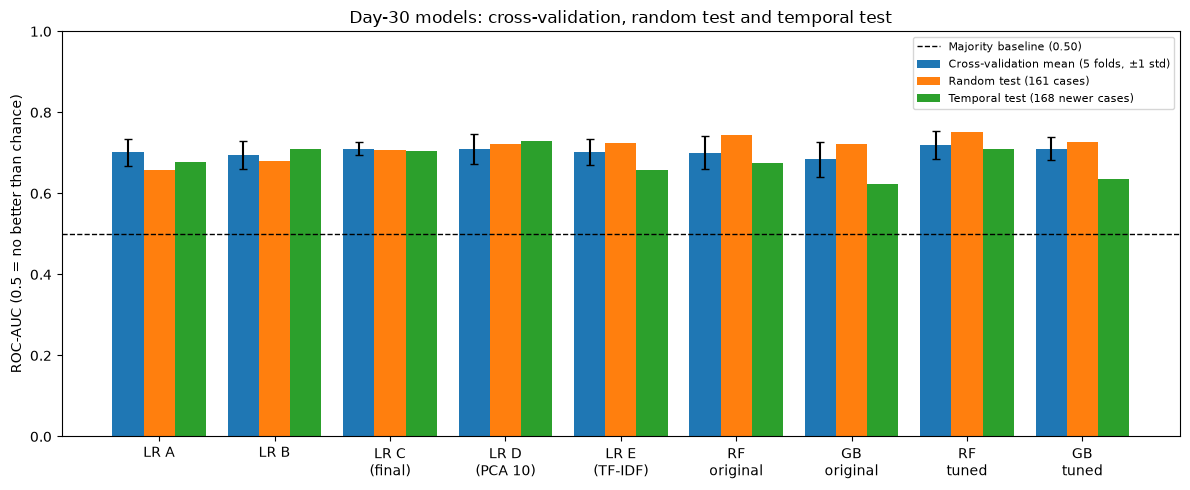

In [40]:
chart_models = [name for name in comparison.index if name != "Majority baseline"]
short_labels = ["LR A", "LR B", "LR C\n(final)", f"LR D\n(PCA {best_components})", "LR E\n(TF-IDF)",
                "RF\noriginal", "GB\noriginal", "RF\ntuned", "GB\ntuned"]
positions = list(range(len(chart_models)))
width = 0.27

plt.figure(figsize=(12, 5))
plt.bar([p - width for p in positions], comparison.loc[chart_models, "CV ROC-AUC"], width,
        yerr=comparison.loc[chart_models, "CV std"], capsize=3, label="Cross-validation mean (5 folds, ±1 std)")
plt.bar(positions, comparison.loc[chart_models, "Random ROC-AUC"], width, label="Random test (161 cases)")
plt.bar([p + width for p in positions], comparison.loc[chart_models, "Temporal ROC-AUC"], width, label="Temporal test (168 newer cases)")
plt.axhline(0.5, color="black", linestyle="--", linewidth=1, label="Majority baseline (0.50)")
plt.xticks(positions, short_labels)
plt.ylim(0, 1)
plt.ylabel("ROC-AUC (0.5 = no better than chance)")
plt.title("Day-30 models: cross-validation, random test and temporal test")
plt.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.savefig(figures_folder / "model_comparison_roc_auc.png", dpi=120)
plt.show()

Every model ranks long cases better than the baseline, but the differences between the models are small. Three results
stand out: **Logistic Regression C** (the final model, the most stable across folds), the **tuned Random Forest** (the
highest cross-validation mean) and **PCA** (the highest temporal-test ROC-AUC). The test results change between the two
tests, so no single test result decides.

### 8.3 Choosing the final model: the one-standard-error rule

**The rule in simple words:** take the model with the highest mean cross-validation ROC-AUC; any model whose mean is
within **one standard error** of it is treated as **competitive**, given how much the folds vary. Among those, prefer the
simplest model that can be explained. This is an exploratory rule of thumb for preferring a simpler model, not a
statistical test of equivalence or significance. The standard error is the fold standard deviation divided by √5 (five folds).

In [41]:
model_scores = comparison.drop(index="Majority baseline")
best_model = model_scores["CV ROC-AUC"].idxmax()
best_mean = model_scores.loc[best_model, "CV ROC-AUC"]
standard_error = model_scores.loc[best_model, "CV std"] / 5 ** 0.5
threshold = best_mean - standard_error

print(f"Highest mean CV ROC-AUC: {best_model} = {best_mean:.3f}")
print(f"Standard error: {standard_error:.3f} -> threshold: {threshold:.3f}")
print()
print("Models within one standard error of the best:")
print(model_scores.loc[model_scores["CV ROC-AUC"] >= threshold, ["CV ROC-AUC", "CV std"]].round(3).to_string())

Highest mean CV ROC-AUC: Random Forest (tuned) = 0.720
Standard error: 0.016 -> threshold: 0.705

Models within one standard error of the best:
                                            CV ROC-AUC  CV std
Model                                                         
Logistic Regression C                            0.710   0.017
Logistic Regression D (PCA, 10 components)       0.709   0.036
Random Forest (tuned)                            0.720   0.035
Gradient Boosting (tuned)                        0.710   0.029


Besides the tuned Random Forest itself, three models are within one standard error of it: Logistic Regression C,
Logistic Regression D (PCA) and the tuned Gradient Boosting. **Logistic Regression C** is the simplest of them whose
features can each be explained (PCA components cannot, and ensembles of many trees are harder to explain), and it has the
smallest variation across folds. It is therefore the **final model**.

Two honest qualifications: this rule was **formalised after** the exploratory experiments (it confirms the preference for
C that the earlier research had already stated), and it does **not** prove that the models are statistically equal or
that one is better. The numerical rule uses only cross-validation results, but the test results had already been seen
during the earlier research, so the tests were not untouched when the rule was formulated.

**Fold by fold**, the tuned Random Forest and Logistic Regression C used exactly the same folds:

In [42]:
fold_scores = cv_results.pivot(index="Fold", columns="Model", values="ROC-AUC")
paired = pd.DataFrame({
    "Logistic Regression C": fold_scores["Logistic Regression C"],
    "Random Forest (tuned)": fold_scores[random_forest_grid.idxmax()],
})
paired["Difference (RF - LR C)"] = paired["Random Forest (tuned)"] - paired["Logistic Regression C"]
paired.round(3)

,Logistic Regression C,Random Forest (tuned),Difference (RF - LR C)
Fold,,,
1,0.736,0.740,0.004
2,0.696,0.677,-0.018
3,0.708,0.728,0.019
4,0.696,0.694,-0.003
5,0.714,0.763,0.049


The tuned Random Forest is better in some folds and worse in others, so the gap of about 0.01 in the mean is not
consistent from fold to fold.

## 9. Error analysis

### 9.1 Train the final model

**Train Logistic Regression C on the random training cases** and predict the random test cases. These are the same steps
as inside the comparison, written out so the final model is easy to find.

In [43]:
final_activities = select_activities(first30, random_train_ids)
final_groups = select_groups(first30, random_train_ids)
X_train_final, X_test_final = features_C(random_train_ids, random_test_ids)

final_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
final_model.fit(X_train_final, y.loc[random_train_ids])

final_probability = final_model.predict_proba(X_test_final)[:, 1]
final_prediction = final_model.predict(X_test_final)
print("Features:", X_train_final.shape[1], "| activity codes:", len(final_activities), "| activity groups:", len(final_groups))
print("Random-test ROC-AUC:", round(roc_auc_score(y.loc[random_test_ids], final_probability), 3))

Features: 40 | activity codes: 15 | activity groups: 16
Random-test ROC-AUC: 0.708


**Also train it on the older cases of the temporal split** and predict the newest cases, for the second confusion matrix.

In [44]:
X_train_temporal, X_test_temporal = features_C(temporal_train_ids, temporal_test_ids)
temporal_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
temporal_model.fit(X_train_temporal, y.loc[temporal_train_ids])
temporal_prediction = temporal_model.predict(X_test_temporal)

### 9.2 Confusion matrices

**Count the four kinds of outcomes** on both tests: long cases found (true positives), long cases missed (false
negatives), false alarms (false positives) and correctly ignored cases (true negatives).

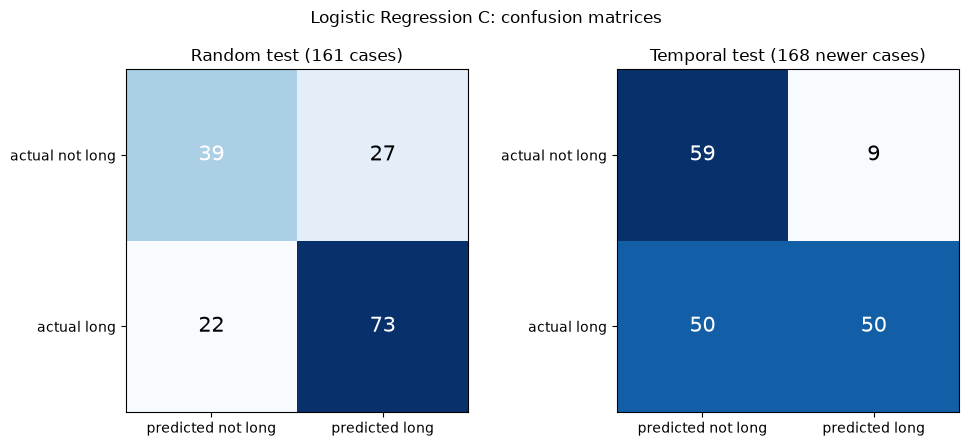

In [45]:
matrices = {
    "Random test (161 cases)": confusion_matrix(y.loc[random_test_ids], final_prediction),
    "Temporal test (168 newer cases)": confusion_matrix(y.loc[temporal_test_ids], temporal_prediction),
}

figure, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for axis, (title, matrix) in zip(axes, matrices.items()):
    axis.imshow(matrix, cmap="Blues")
    for i in range(2):
        for j in range(2):
            text_color = "white" if matrix[i, j] > matrix.max() / 2 else "black"
            axis.text(j, i, matrix[i, j], ha="center", va="center", fontsize=15, color=text_color)
    axis.set_xticks([0, 1], ["predicted not long", "predicted long"])
    axis.set_yticks([0, 1], ["actual not long", "actual long"])
    axis.set_title(title)
figure.suptitle("Logistic Regression C: confusion matrices")
plt.tight_layout()
plt.savefig(figures_folder / "model_final_confusion_matrices.png", dpi=120)
plt.show()

On the random test, the model finds 73 of the 95 long cases (recall 0.768) and 73 of its 100 warnings are right
(precision 0.730). On the newer cases it is more cautious: it flags only 59 cases, 50 of them correctly (precision
0.847), but it misses 50 of the 100 long cases (recall 0.50). So when it warns it is usually right, but it misses many
long cases, especially among newer cases.

### 9.3 Examples of errors

**Make a table of the random test cases** with the prediction, the real outcome and a few features, and label every case
as a true or false positive or negative.

In [46]:
errors = X_test_final[["events_first30", "unique_activities_first30", "days_since_last_event", "highest_main_stage"]].copy()
errors["probability_long"] = final_probability
errors["predicted_long"] = final_prediction
errors["actually_long"] = y.loc[random_test_ids].values
errors["recorded_span_days"] = active.loc[random_test_ids, "duration_days"].round(1).values

errors["outcome"] = "true negative"
errors.loc[(errors["predicted_long"] == 1) & (errors["actually_long"] == 1), "outcome"] = "true positive"
errors.loc[(errors["predicted_long"] == 1) & (errors["actually_long"] == 0), "outcome"] = "false positive"
errors.loc[(errors["predicted_long"] == 0) & (errors["actually_long"] == 1), "outcome"] = "false negative"
errors["outcome"].value_counts()

outcome
true positive     73
true negative     39
false positive    27
false negative    22
Name: count, dtype: int64

**False positives:** the five not-long cases the model was most sure were long.

In [47]:
false_positives = errors[errors["outcome"] == "false positive"].sort_values("probability_long", ascending=False)
false_positives.head().round(2)

,events_first30,unique_activities_first30,days_since_last_event,highest_main_stage,probability_long,predicted_long,actually_long,recorded_span_days,outcome
case:concept:name,,,,,,,,,
3396308,8,8,19.60,0,0.93,1,0,61.0,false positive
3234466,3,3,22.47,0,0.93,1,0,50.0,false positive
3286102,4,4,15.61,0,0.91,1,0,51.0,false positive
2830183,9,8,10.96,1,0.90,1,0,53.6,false positive
2831567,9,8,13.96,1,0.89,1,0,51.0,false positive


These cases had little recent activity at day 30 and had not yet reached later main stages, which is what most long cases
look like, but their recorded activity span stayed within 63 days (several only just: a span close to the threshold).

**False negatives:** the five long cases the model was most sure were not long.

In [48]:
false_negatives = errors[errors["outcome"] == "false negative"].sort_values("probability_long")
false_negatives.head().round(2)

,events_first30,unique_activities_first30,days_since_last_event,highest_main_stage,probability_long,predicted_long,actually_long,recorded_span_days,outcome
case:concept:name,,,,,,,,,
4691712,29,29,1.45,4,0.15,0,1,64.0,false negative
7835964,15,15,23.00,1,0.23,0,1,215.5,false negative
7734076,12,12,26.57,1,0.24,0,1,298.0,false negative
6499483,12,12,15.53,1,0.31,0,1,396.0,false negative
7796069,12,12,17.00,1,0.32,0,1,108.0,false negative


One missed case was busy and advanced at day 30 (29 events, main stage 4) and only just crossed the threshold (64.0
days). The others had an ordinary start (12–15 events, main stage 1) and then had recorded activity spans of 108 to 396 days.
The available day-30 features did not reveal the later long recorded activity spans of these cases. Other information
may have helped, but it is not available in the current feature set.

### 9.4 Patterns in the errors

**Compare the average features of the four outcome groups.**

In [49]:
errors.groupby("outcome")[["events_first30", "days_since_last_event", "highest_main_stage", "probability_long", "recorded_span_days"]].mean().round(2)

,events_first30,days_since_last_event,highest_main_stage,probability_long,recorded_span_days
outcome,,,,,
false negative,12.95,21.51,1.14,0.39,155.82
false positive,12.33,16.68,0.81,0.72,51.11
true negative,22.21,15.81,2.46,0.31,50.23
true positive,17.00,15.91,1.53,0.72,189.21


Cases that the model correctly calls not long (true negatives) had clearly the most activity and progress by day 30
(about 22 events and main stage 2.5 on average). The errors sit in between: **false positives and false negatives look
alike at day 30** (about 12–13 events, main stage about 1), but their recorded activity spans were very different (51 vs
156 days on average). The current day-30 features and model did not clearly distinguish these cases, which is the main
limit of the model. This describes the errors in one
test set; it does not explain why cases take long.

**For context, the tuned Random Forest** on the same random test cases:

In [50]:
X_train_rf, X_test_rf = features_A(random_train_ids, random_test_ids)
random_forest_model = clone(tuned_random_forest).fit(X_train_rf, y.loc[random_train_ids])
pd.DataFrame(confusion_matrix(y.loc[random_test_ids], random_forest_model.predict(X_test_rf)),
             index=["actual not long", "actual long"], columns=["predicted not long", "predicted long"])

,predicted not long,predicted long
actual not long,33,33
actual long,15,80


The tuned Random Forest flags more cases (113 of 161), so it finds more long cases (recall 0.842) but raises more false
alarms; on the newer cases it flags only 47 cases and misses most long ones (recall 0.42, section 8.1). Its warnings
change more between the two tests than those of Logistic Regression C.

## 10. Interpretation

**Read the coefficients of the final model.** All features are standardised (rescaled to the same spread) before the
Logistic Regression, so the coefficients can be compared with each other: a **positive** coefficient means that a higher
value of that feature raises the model's estimated log-odds of a long case (and so its estimated probability of
"long"), when all the other features are held fixed; a **negative** coefficient lowers it. Because the features are
standardised, each coefficient is the change for one standard deviation of that feature. The whole table is saved
to `docs/results/final_model_coefficients.csv`.

In [51]:
coefficients = pd.DataFrame({
    "feature": X_train_final.columns,
    "coefficient": final_model.named_steps["logisticregression"].coef_[0],
})
coefficients.to_csv(results_folder / "final_model_coefficients.csv", index=False)

largest = coefficients.reindex(coefficients["coefficient"].abs().sort_values(ascending=False).index).head(15)
largest.round(3)

,feature,coefficient
33,grp_09_AH,-1.051
12,act_04_BPT_005,-0.919
25,grp_01_HOOFD_4xx,-0.741
1,unique_activities_first30,0.731
0,events_first30,0.718
4,events_first15,0.592
21,act_01_HOOFD_200,-0.515
13,act_01_HOOFD_065_2,-0.505
2,unique_resources_first30,-0.488
7,act_01_HOOFD_030_1,-0.479


**Chart of the 15 largest coefficients** (by size, positive and negative).

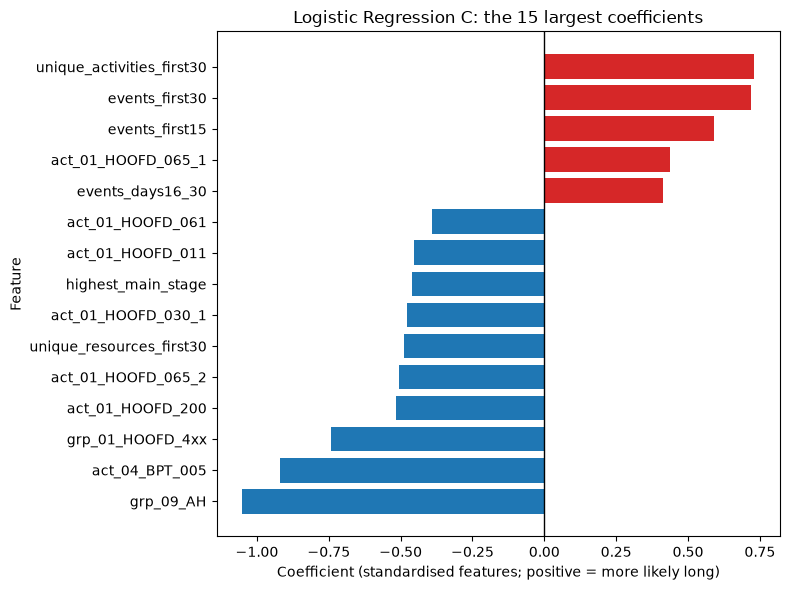

In [52]:
chart_data = largest.sort_values("coefficient")
colors = ["tab:red" if value > 0 else "tab:blue" for value in chart_data["coefficient"]]

plt.figure(figsize=(8, 6))
plt.barh(chart_data["feature"], chart_data["coefficient"], color=colors)
plt.axvline(0, color="black", linewidth=1)
plt.title("Logistic Regression C: the 15 largest coefficients")
plt.xlabel("Coefficient (standardised features; positive = more likely long)")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig(figures_folder / "model_final_coefficients.png", dpi=120)
plt.show()

The largest coefficients are **negative** ones for certain activity codes and groups (for example `grp_09_AH`,
`act_04_BPT_005` and `grp_01_HOOFD_4xx`) and for `highest_main_stage`: when these steps were already recorded by day 30,
the model predicts "long" less often. In plain words, a case that has already progressed further in its first 30 days is
less likely to be predicted long. The count features have **positive** coefficients, but read the cautions:

- Several features overlap strongly (for example `events_first30` and `unique_activities_first30`, and the redundant
  count features), so the model can split one effect between them; single coefficients should not be over-read.
- A coefficient shows what the model **uses**, not what **causes** a case to take long.

**For comparison, the tuned Random Forest's built-in feature importance:** how much the splits on each feature reduced
impurity (the mixing of long and not-long cases in the tree nodes), averaged over all trees. It is not simply the
number of times a feature is used in a split.

In [53]:
importance = pd.DataFrame({"feature": X_train_rf.columns, "importance": random_forest_model.feature_importances_})
importance.sort_values("importance", ascending=False).head(10).round(3)

,feature,importance
1,unique_activities_first30,0.151
0,events_first30,0.140
2,unique_resources_first30,0.132
5,events_days16_30,0.104
6,days_since_last_event,0.099
4,events_first15,0.094
9,act_01_HOOFD_101,0.060
7,act_01_HOOFD_030_1,0.051
21,act_01_HOOFD_200,0.021
8,act_01_HOOFD_030_2,0.020


The Random Forest relies mostly on the count features. Importance values are spread out over correlated features, this
kind of importance can favour features with many different values, and, like coefficients, they are not causes.

## 11. Limitations & ethics

**Limitations of the results**

- The target is the **recorded activity span**, not a verified administrative completion time; the recorded end date
  often disagrees with the last recorded event.
- The **63-day threshold is exploratory**: the median recorded activity span of the cases with a recorded end date, chosen
  with all of them, including the later test cases. It is not a legal deadline.
- The cohort is **retrospective**: day-30 eligibility uses each case's last recorded event, which is only known
  afterwards, and only cases with a recorded end date are included (the newest cases are under-represented).
- **Timestamp precision is limited**: 45.9% of events are at exactly local midnight and 30,433 are tied, so the order of
  tied events is uncertain and events close to the day-30 cutoff may be placed imprecisely.
- The test cases were **reused** across the research, and 138 of the 168 temporal test cases were earlier training cases:
  the temporal test is a robustness check, not an independent final validation.
- Many settings were compared on the **same folds**, so the best scores are slightly optimistic; the differences between
  the models are **small**; and the selection rule was formalised **after** the experiments.
- One historical Dutch municipality (2010–2015); **not SPAR data**. The model is **not validated for operational use**.

**Ethics and responsible use**

- The resource IDs are not used to judge people: this research must **not** be used to rank or evaluate employees.
- A prediction must **not** decide anything about a case or an applicant automatically. At most, a validated future model
  could help people decide which cases to look at earlier.
- The model misses many long cases, so a "not long" prediction is no guarantee; relying on it could delay attention to
  cases that need it.
- No causal, financial, legal or production-readiness claims follow from these results.

## 12. Conclusion & next steps

**What worked:** information from the first 30 days gives a **modest** early-warning signal. Logistic Regression C ranks
long cases clearly above chance (ROC-AUC about 0.71 in cross-validation and on both tests), and adding activity groups to
the original features gave a small improvement. Tuning improved the Random Forest to the highest cross-validation score,
and PCA gave the highest temporal-test result, but neither was clearly better than the simpler model.

**What did not work:** the TF-IDF text features did not improve cross-validation and did worse on newer cases (the
descriptions mostly repeat the activity codes). Earlier, whole-case regressions could not give early warnings, and
day-14 information was too weak. All models still miss many long cases at the default threshold.

**What I would try next:** test the approach on **new data that was never used during development**, ideally with a known
open/closed status at the prediction time and a target agreed with people who handle the cases (for example a documented
deadline). With SPAR's own historical data, this would be a future research project, not a continuation of this model.

### Saving the final model

**Save the final model** (Logistic Regression C trained on the **random training split**, 677 cases) together with what is
needed to use it again: the fitted pipeline (scaler + model), the feature names in order, the chosen activity codes and
groups, and the versions. The file goes to the git-ignored `models/` folder. An existing file is **not overwritten**, and
it is **not loaded** either, because this notebook cannot know where an existing file came from.

In [54]:
saved_model = {
    "model": final_model,
    "feature_names": list(X_train_final.columns),
    "activities": final_activities,
    "groups": final_groups,
    "trained_on": "random training split (677 day-30 cases)",
    "target": "long_case = recorded activity span > 63 days; features from the first 30 days (see notebooks/02_modelling.ipynb)",
    "python_version": platform.python_version(),
    "sklearn_version": sklearn.__version__,
}

model_file = models_folder / "logistic_regression_c.pkl"
if model_file.exists():
    print("models/logistic_regression_c.pkl already exists: it was NOT overwritten and will NOT be loaded.")
    # for the reload check, save this run's model to a new temporary folder instead
    trusted_file = Path(tempfile.mkdtemp()) / "logistic_regression_c.pkl"
else:
    trusted_file = model_file
with open(trusted_file, "wb") as file:
    pickle.dump(saved_model, file)
if trusted_file == model_file:
    print("Saved: models/logistic_regression_c.pkl")
else:
    print("This run's model was saved to a temporary file for the reload check.")
print("Size:", trusted_file.stat().st_size, "bytes")

Saved: models/logistic_regression_c.pkl
Size: 3976 bytes


**Load it again and check that it predicts exactly the same.** Loading a pickle file can run hidden code, so only
`trusted_file` is loaded: the file that **this run** has just written (either the new `models/` file or the temporary
copy). A file that already existed is never loaded. The checks compare the feature names and their order, the chosen
activities and groups, and every predicted probability; the temporary copy is deleted afterwards.

In [55]:
with open(trusted_file, "rb") as file:
    loaded = pickle.load(file)

reloaded_probability = loaded["model"].predict_proba(X_test_final[loaded["feature_names"]])[:, 1]
assert loaded["feature_names"] == list(X_test_final.columns), "Feature names or order changed"
assert loaded["activities"] == final_activities and loaded["groups"] == final_groups, "Chosen activities or groups changed"
assert (reloaded_probability == final_probability).all(), "Predictions changed after reloading"
print("Same feature names and order: True")
print("Same chosen activities and groups: True")
print("Predictions identical after reloading: True")

if trusted_file != model_file:
    trusted_file.unlink()
    trusted_file.parent.rmdir()


Same feature names and order: True
Same chosen activities and groups: True
Predictions identical after reloading: True


The model written by this run reproduces its predictions exactly after reloading. It is a **research artefact** for reproducing these results, not an
operational system.